# Stage 1: What drives engagement rate? Regression results

**Question.** Which content features (ICP segment, content pillar, format, timing), controlling for reach,
are associated with a post's engagement rate, and how well can engagement be predicted from them?

**What this notebook is.** It presents the committed model runs; it does not refit them. Every number comes
from a run folder under `outputs/runs/`, produced by `python -m modeling.run_regression` and
`python -m modeling.run_sensitivity` (code in `modeling/`). The provenance cell below shows which commit and
which master file produced each run. The one exception is the Stage 2 preview at the end, which refits one model
and checks that it reproduces the committed coefficients exactly.

**Design (agreed before modeling)**

| | |
|---|---|
| Data | `data/Hidalga_Master_Data_v3.xlsx`, 390 posts (1 Facebook post with 0 impressions has no rate) |
| Unit | one row per platform post; ICP segments and pillars as 0/1 columns (posts can carry several) |
| Target | `ENGAGEMENT_RATE_UNIFIED_PCT` = (reactions + comments + shares + clicks) / impressions × 100, in percentage points |
| Main analysis | **one model per platform** (Facebook 123, Instagram 130, LinkedIn 137 posts); a **pooled** model is a check only |
| Reach control | `log2(impressions)` in every main model; its coefficient = change in rate per doubling of impressions |
| Models | reference (mean), OLS (HC3 robust SEs; pooled: clustered by content piece), ridge, lasso, elastic net |
| Validation | repeated 5-fold × 10 CV; regularized models tuned by nested CV; cross-posted content kept in one fold |
| Trust checks | 500 bootstrap refits (stability), permutation importance on held-out folds, 5 sensitivity variants |

**Reading the results.** Coefficients are *associations*, not causal effects. With ~130 posts per platform, a
confidence interval that crosses 0 means the data cannot distinguish the effect from none. It does not show
there is no effect.

## 1. Setup and provenance

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

REPO = Path("..").resolve()
sys.path.insert(0, str(REPO))
from modeling.features import file_sha256, load_config  # noqa: E402

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

RUNS = {   # the committed runs this notebook reports
    "baseline OLS (step 2)": REPO / "outputs/runs/2026-10-25_step2_baseline",
    "regularized (step 3)": REPO / "outputs/runs/2026-10-25_step3_regularized",
    "stability & importance (step 4)": REPO / "outputs/runs/2026-10-25_step4_importance",
    "sensitivity (step 5)": REPO / "outputs/runs/2026-10-25_step5_sensitivity",
}
MAIN = RUNS["stability & importance (step 4)"]     # contains steps 2–4 outputs
SENS = RUNS["sensitivity (step 5)"]
CONFIG = load_config()
current_sha = file_sha256(REPO / CONFIG["master"])

prov = []
for name, path in RUNS.items():
    info = json.loads((path / "run_info.json").read_text())
    prov.append({"run": name, "folder": path.name, "commit": info["git"]["commit"][:7],
                 "clean_commit": not info["git"]["uncommitted_changes"], "master": info["master"],
                 "master_matches_current": info["master_sha256"] == current_sha, "seed": info["seed"]})
prov = pd.DataFrame(prov)
display(prov)
assert prov["master_matches_current"].all(), "A run was made on a different master file than the current one."

,run,folder,commit,clean_commit,master,master_matches_current,seed
0,baseline OLS (step 2),2026-10-25_step2_baseline,a7d05ea,True,data/Hidalga_Master_Data_v3.xlsx,True,26
1,regularized (step 3),2026-10-25_step3_regularized,33f7a4f,True,data/Hidalga_Master_Data_v3.xlsx,True,26
2,stability & importance (step 4),2026-10-25_step4_importance,9bf3c6d,True,data/Hidalga_Master_Data_v3.xlsx,True,26
3,sensitivity (step 5),2026-10-25_step5_sensitivity,ee1a6fd,True,data/Hidalga_Master_Data_v3.xlsx,True,26


In [2]:
def fig(run, name, width=1100):
    display(Image(filename=str(run / "figures" / name), width=width))


def read(run, name):
    return pd.read_csv(run / name)


LABEL = {"log2_impressions": "Reach: impressions doubled", "WEEKEND": "Timing: weekend",
         "AFTER_11": "Timing: posted 11am or later", "BOOSTED": "LinkedIn: also paid-boosted",
         "IN_EXPERIMENT_PERIOD": "Period: Q2–Q3 experiment"}
lab = lambda f: LABEL.get(f, f)

## 2. Features in the main models
Reference categories: **Image** for format, **Thought Leadership & Industry Insights** for pillar (378 of 391 posts
carry exactly one pillar, so one must be omitted). All four ICP segments are kept (posts carry 1–3, and the
VIF check below confirms no collinearity problem). "posts with feature" counts posts with a 1 in each 0/1 column.

In [3]:
ols = read(MAIN, "coefficients_ols.csv")
feat = (ols[(ols["feature"] != "const") & ols["platform"].ne("pooled")]
        .pivot_table(index="feature", columns="platform", values="posts_with_feature", aggfunc="first", sort=False))
feat.index = feat.index.map(lab)
display(feat.apply(lambda c: c.map(lambda v: "–" if pd.isna(v) else f"{int(v)}")).rename_axis("posts with feature"))
vif = read(MAIN, "vif.csv")
print("Max VIF per model:", vif.groupby("platform")["vif"].max().round(2).to_dict(), "(>5 would be a concern)")

platform,Facebook,Instagram,LinkedIn
posts with feature,,,
ICP: Oncology Clinic Leader,32,34,36
ICP: Oncology Financial Leader,22,23,25
ICP: Oncology Operations Leader,82,87,92
ICP: Oncology Technical Leader,28,31,32
Pillar: Events & Partnerships,23,23,25
Pillar: Patient-Centered Storytelling,9,10,13
Pillar: Product Development & Innovations,9,11,12
Pillar: Team Spotlights & Company Culture,36,37,39
Format: Multi-Image,22,–,10


Max VIF per model: {'Facebook': 1.89, 'Instagram': 2.04, 'LinkedIn': 1.76, 'pooled': 4.27} (>5 would be a concern)


## 3. How well can engagement rate be predicted?
Held-out performance on the same 50 CV splits for every model. The **reference** model always predicts the
training mean, so a useful model must beat it. R² < 0 means worse than the mean.

platform,Facebook,Instagram,LinkedIn,pooled
held-out R²,,,,
reference (mean),-0.052,-0.057,-0.075,-0.014
OLS,-0.203,0.372,-0.344,0.221
Ridge,-0.045,0.413,-0.003,0.233
Lasso,-0.074,0.437,0.001,0.240
Elastic net,-0.052,0.438,-0.005,0.241


platform,Facebook,Instagram,LinkedIn,pooled
held-out MAE (pts),,,,
reference (mean),8.013,6.465,5.066,7.489
OLS,8.379,4.906,5.259,6.083
Ridge,8.027,4.820,4.819,6.052
Lasso,8.111,4.698,4.660,5.981
Elastic net,8.080,4.688,4.721,5.998


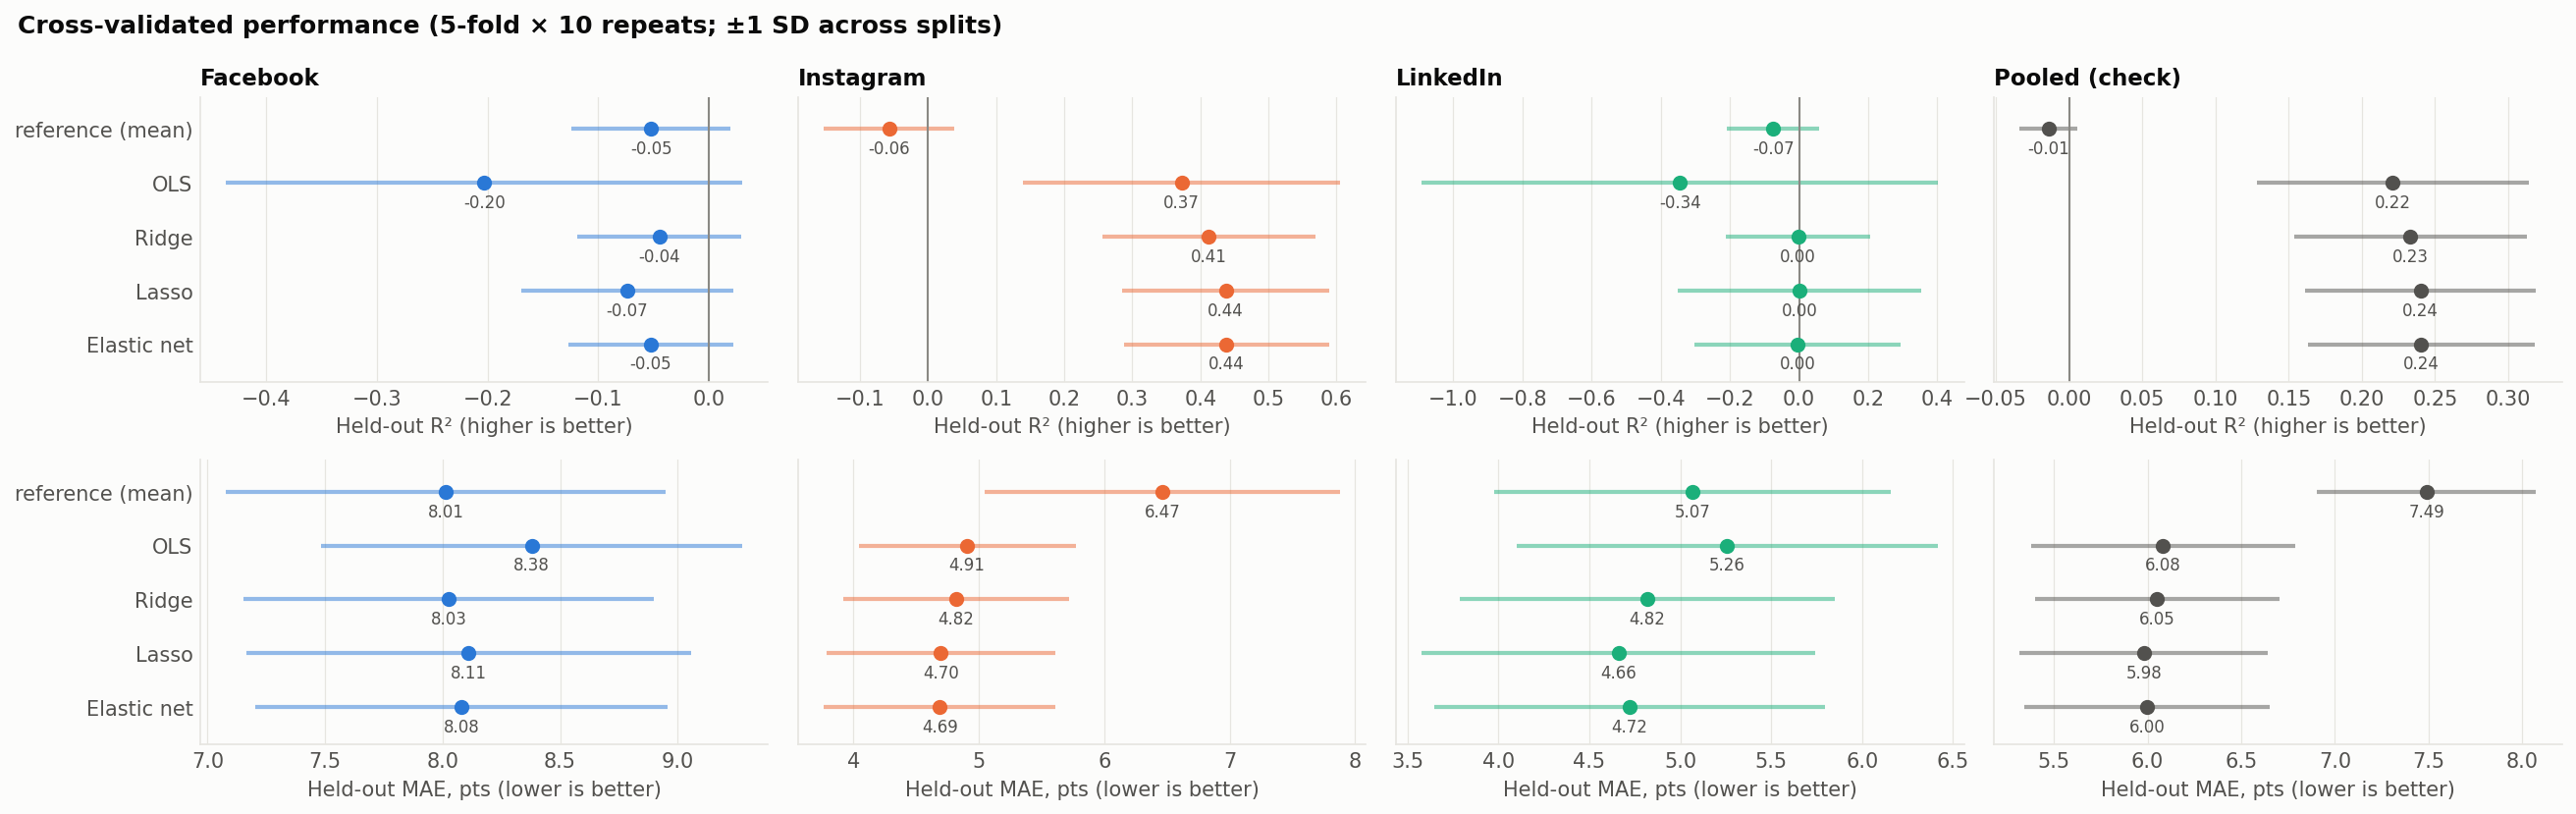

In [4]:
cv = read(MAIN, "cv_summary.csv")
display(cv.pivot(index="model", columns="platform", values="r2_mean")
        .reindex(["reference (mean)", "OLS", "Ridge", "Lasso", "Elastic net"])
        .rename_axis("held-out R²"))
display(cv.pivot(index="model", columns="platform", values="mae_mean")
        .reindex(["reference (mean)", "OLS", "Ridge", "Lasso", "Elastic net"])
        .rename_axis("held-out MAE (pts)"))
# The run folder's cv_performance.png has broken value labels (plot bug fixed after this run, commit 8fa1bd2),
# so the chart is redrawn here from the run's own cv_scores.csv with the fixed plotting code. Nothing is refit.
from modeling import plots  # noqa: E402
cv_fig = Path("figures/nb02_cv_performance.png")
plots.cv_plot(read(MAIN, "cv_scores.csv"), CONFIG["platforms"] + ["pooled"], cv_fig)
display(Image(filename=str(cv_fig), width=1100))

**Reading it**
- **Instagram is predictable.** Elastic net explains **≈44%** of held-out variation (MAE 4.7 pts vs 6.5 for the mean).
  Section 6 shows a log-scale target lifts this to ≈57%.
- **LinkedIn:** OLS overfits (R² −0.34). Regularization brings it back to the mean's level and cuts typical error by
  ~8% (MAE 4.7 vs 5.1). R² stays ≈0 because a single post (3 impressions, 66.7%) dominates squared error; without
  it R² is ≈0.19 (section 6).
- **Facebook is not predictable from these features.** No model beats the mean, and lasso drops every feature. Its
  audience is tiny (6–18 followers) and many rates rest on <10 impressions.
- **Pooled (check):** R² ≈0.24, mostly from platform level, reach and format.

## 4. Effect sizes
### 4.1 Baseline OLS, within each platform
Coefficient in percentage points with 95% CI (robust SEs). Each panel has its own x-scale.

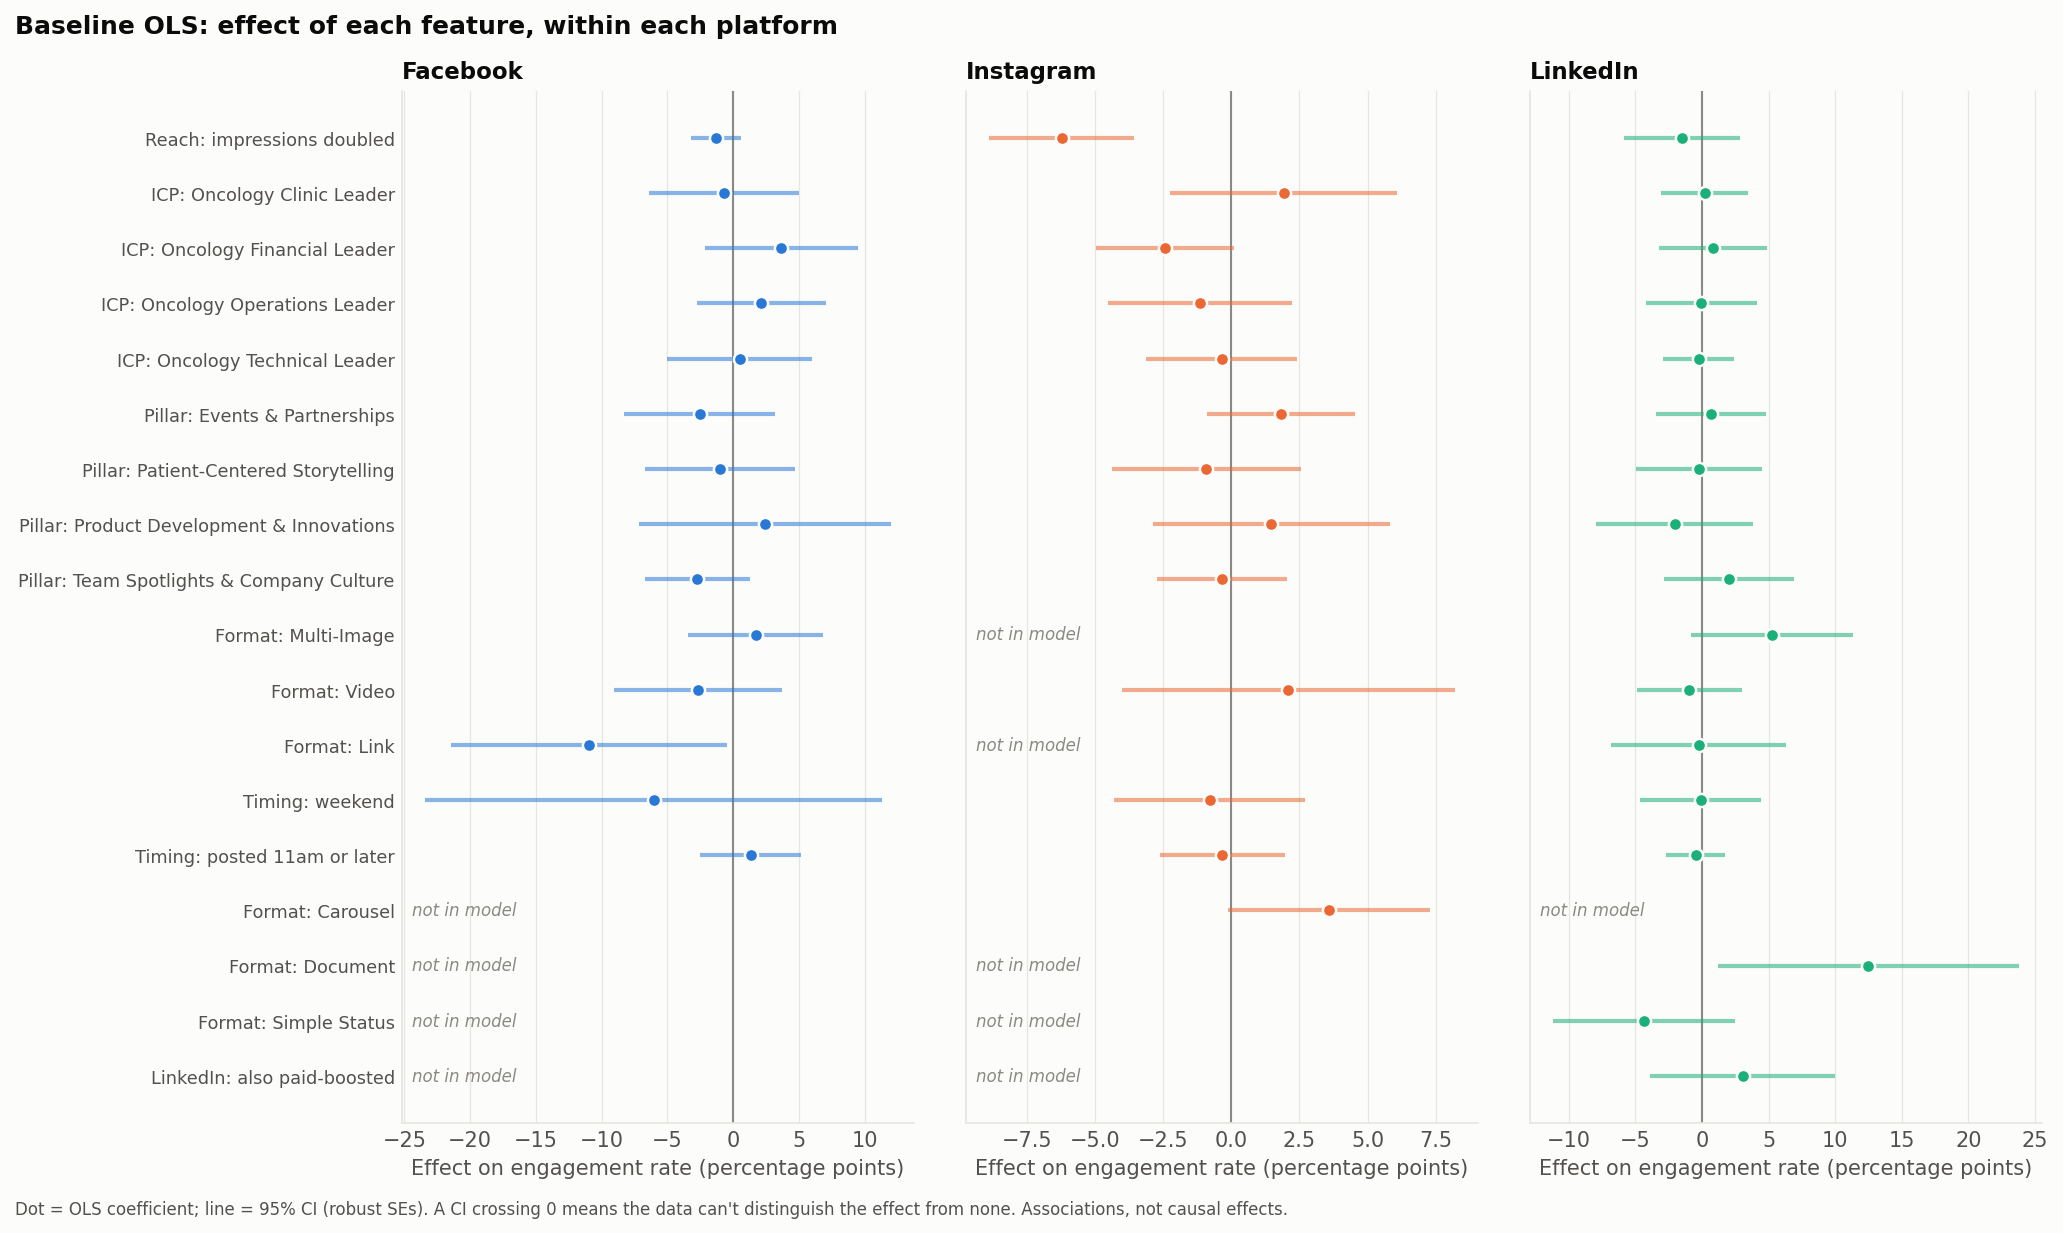

platform,feature,coef_pts,ci_lo,ci_hi,p_value,posts_with_feature
Facebook,Format: Link,-10.967475,-21.487746,-0.447203,0.041025,8
Instagram,Reach: impressions doubled,-6.219478,-8.872121,-3.566834,0.000004,–
LinkedIn,Format: Document,12.477466,1.189411,23.765522,0.030274,13
pooled,Reach: impressions doubled,-2.130573,-3.433121,-0.828025,0.001346,–
pooled,Format: Multi-Image,3.568682,0.231572,6.905793,0.036085,32
pooled,Format: Video,-3.456199,-5.704153,-1.208245,0.002583,42
pooled,Format: Link,-4.725564,-9.272497,-0.178632,0.041654,26
pooled,Format: Simple Status,-5.715693,-9.472312,-1.959073,0.002863,6
pooled,Platform: Instagram,5.076331,2.570467,7.582195,0.000072,130


In [5]:
fig(MAIN, "coef_ols_by_platform.png")
sig = ols[(ols["feature"] != "const") & ((ols["ci_lo"] > 0) | (ols["ci_hi"] < 0))].copy()
sig["feature"] = sig["feature"].map(lab)
display(sig[["platform", "feature", "coef_pts", "ci_lo", "ci_hi", "p_value", "posts_with_feature"]]
        .rename_axis(None).reset_index(drop=True).style.format(precision=2)
        .format({"posts_with_feature": lambda v: "–" if pd.isna(v) else f"{int(v)}"}).hide(axis="index")
        .set_caption("OLS effects whose 95% CI excludes 0"))

### 4.2 OLS vs. regularized estimates
Ridge / lasso / elastic net shrink effects toward 0, and lasso / elastic net drop features that don't carry
reliable signal. Where they agree with OLS, the effect is not just noise fitted by an unpenalized model.

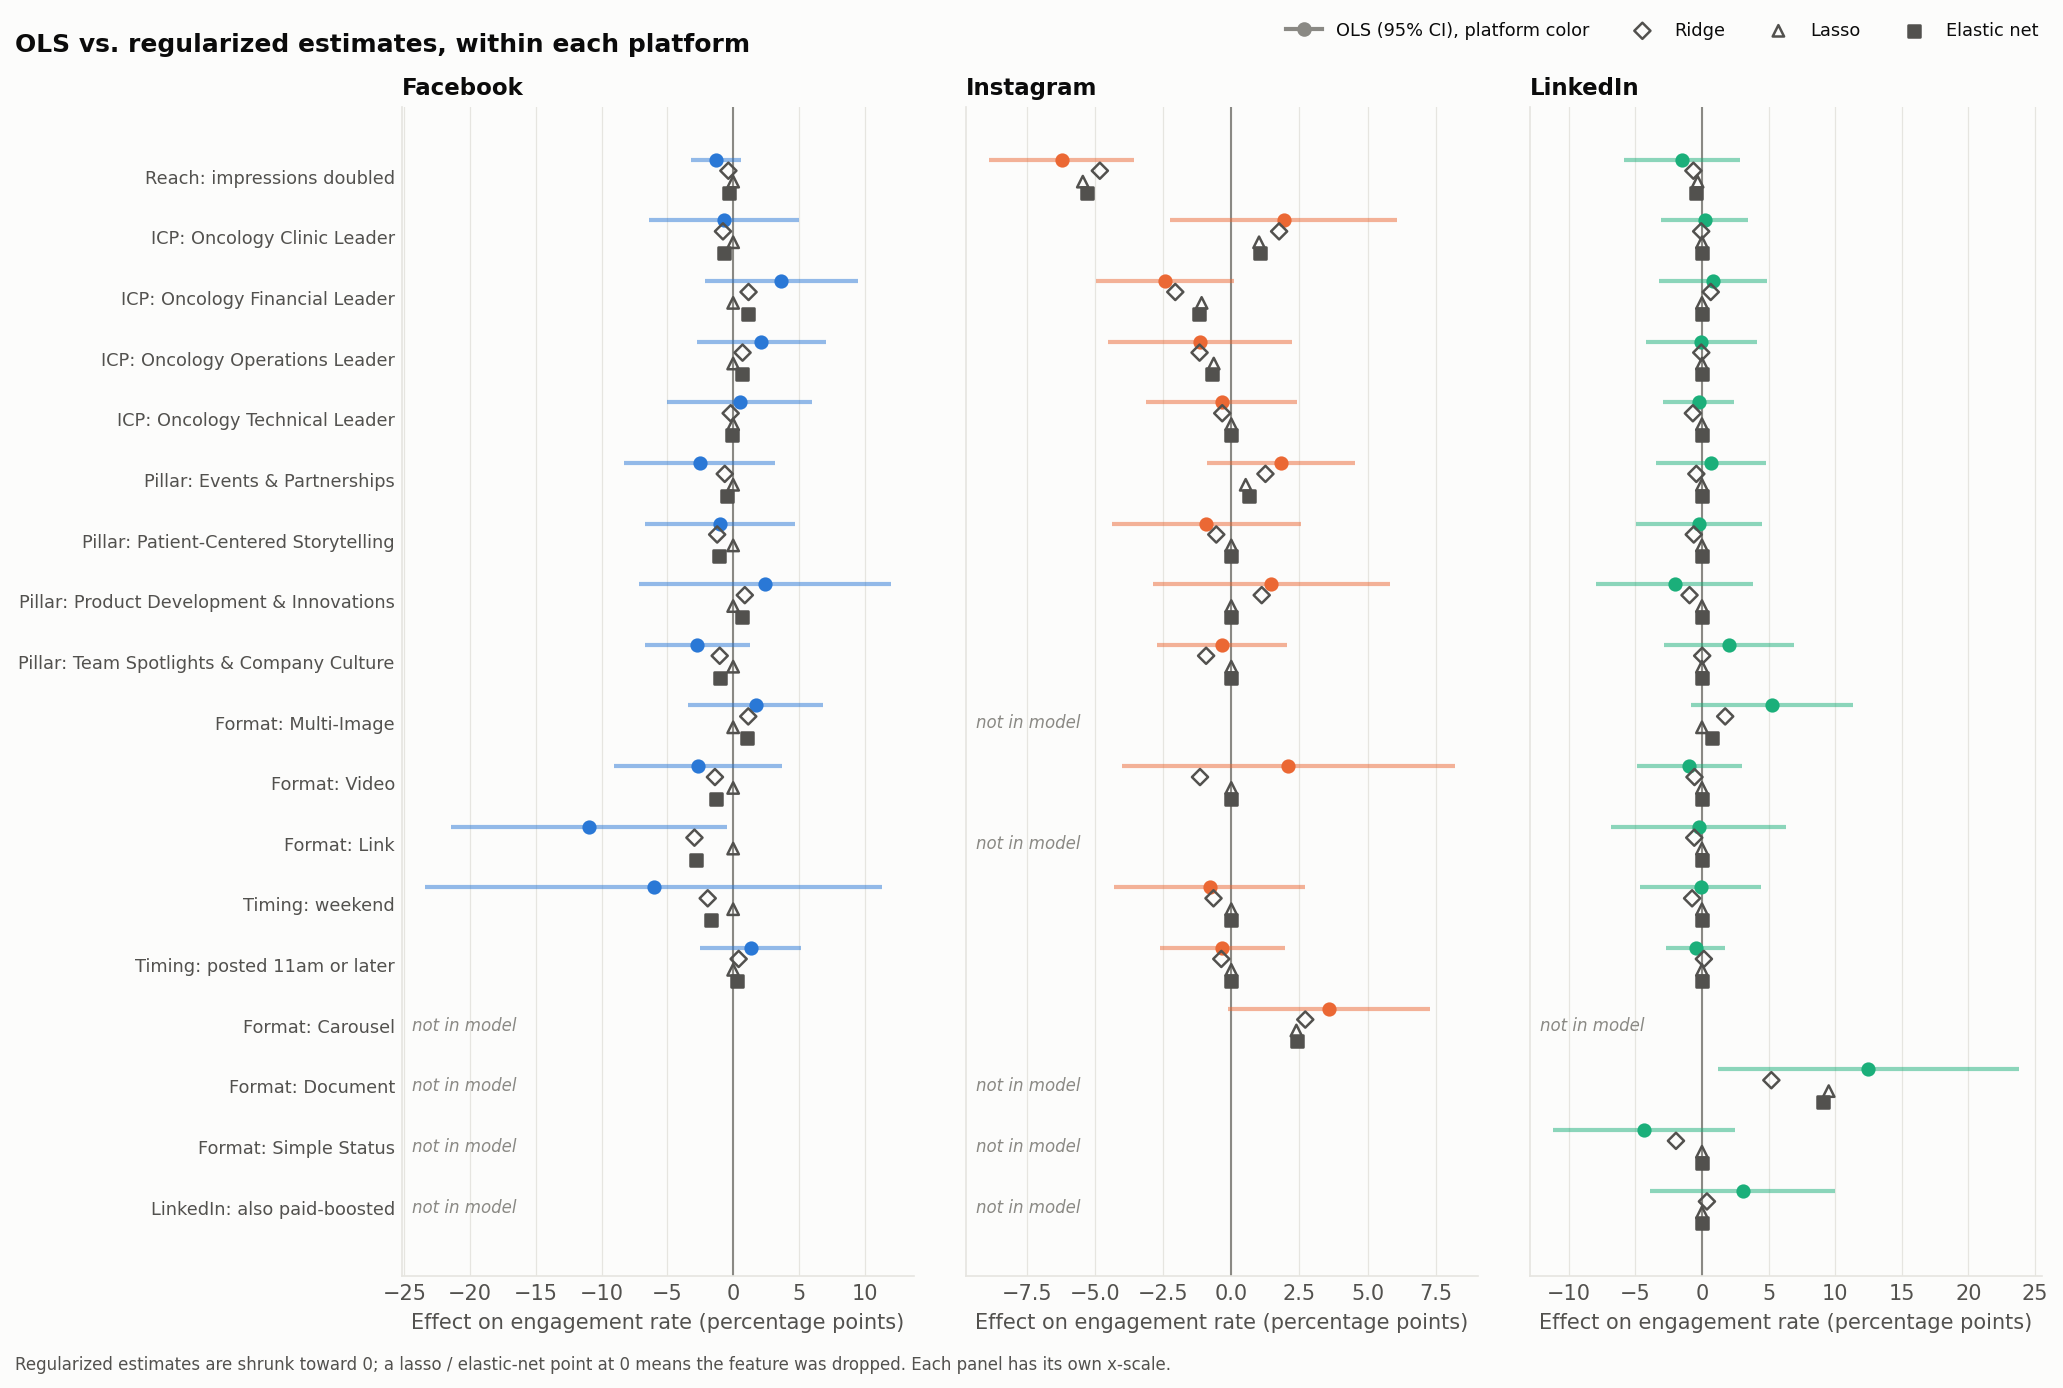

In [6]:
fig(MAIN, "coef_compare_by_platform.png")

## 5. Which features matter, and how stable are they?
### 5.1 Permutation importance (elastic net, held-out folds)
How much worse held-out predictions get (MAE, pts) when a feature group is shuffled. Near 0 = the model does
not rely on it.

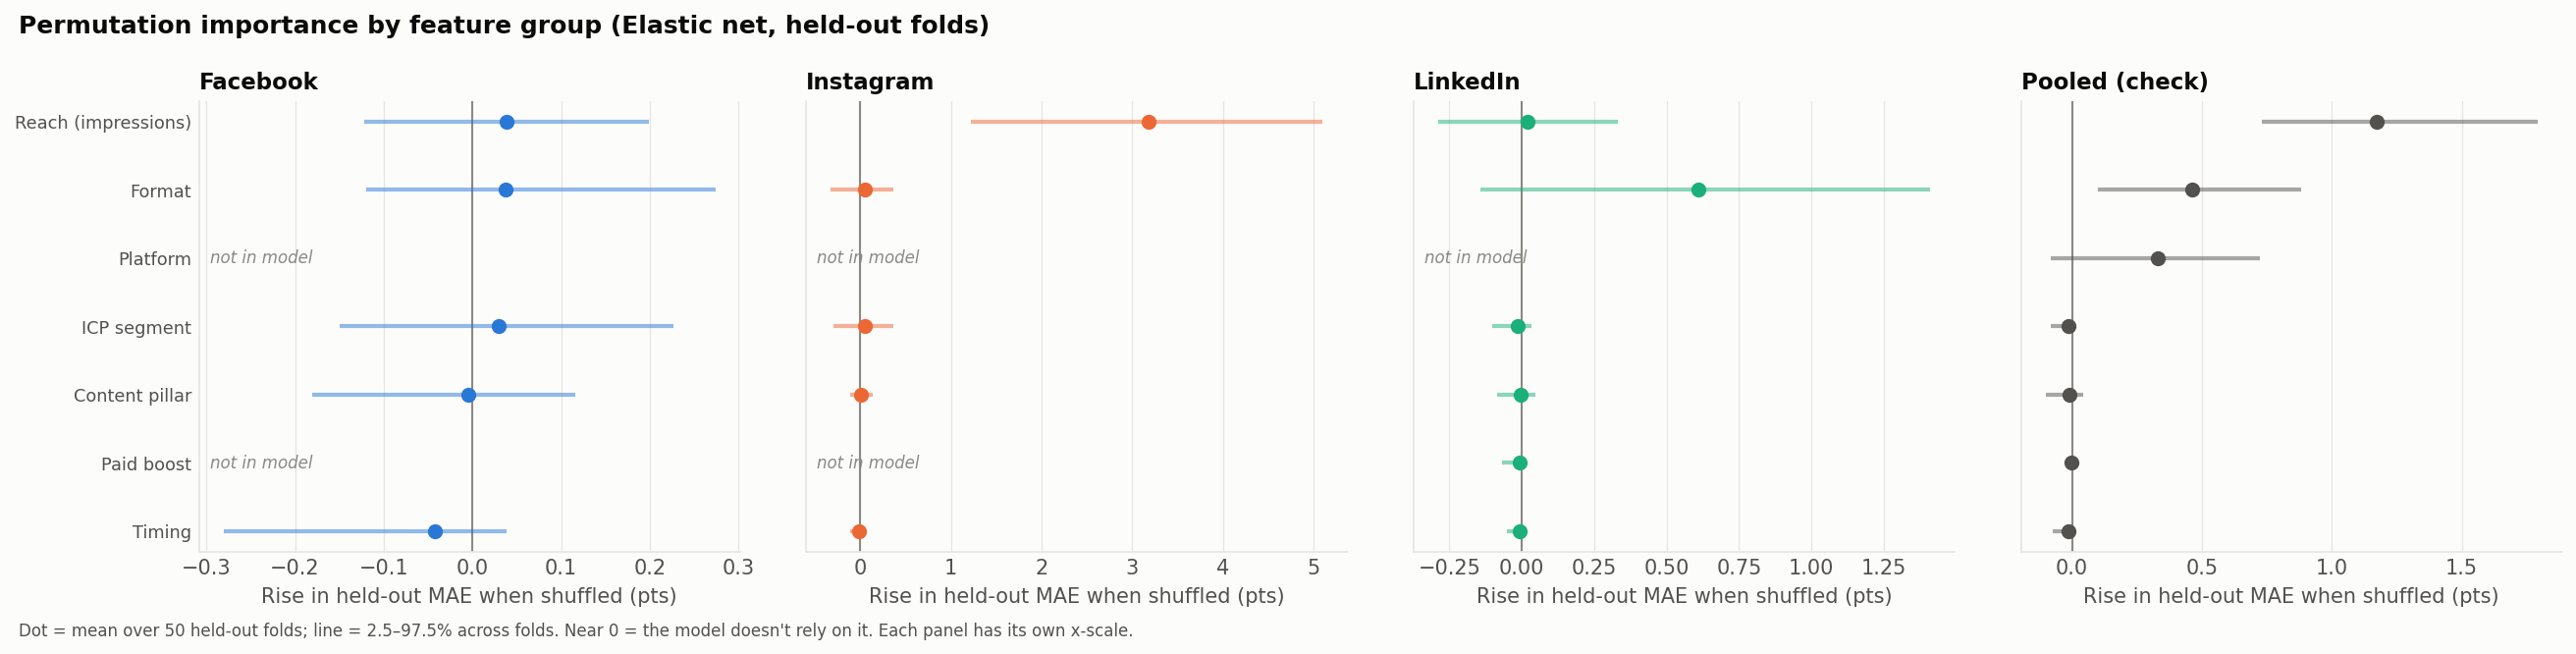

platform,Facebook,Instagram,LinkedIn,pooled
MAE rise when shuffled (pts),,,,
Reach (impressions),0.038,3.181,0.018,1.173
Format,0.037,0.055,0.609,0.463
Platform,NaN,NaN,NaN,0.332
Paid boost,NaN,NaN,-0.006,-0.003
Content pillar,-0.005,0.010,-0.005,-0.011
Timing,-0.043,-0.010,-0.006,-0.012
ICP segment,0.029,0.053,-0.013,-0.014


In [7]:
fig(MAIN, "importance_groups.png")
imp = read(MAIN, "importance.csv")
g = imp[imp["level"] == "group"]
display(g.pivot(index="unit", columns="platform", values="mae_rise_mean")
        .sort_values("pooled", ascending=False).rename_axis("MAE rise when shuffled (pts)"))

### 5.2 Bootstrap stability (500 refits)
Share of refits that keep each feature. On Facebook the elastic net chose a ridge-like mix and keeps nearly
everything with tiny effects, so read **lasso** there (no Facebook feature reaches 60%).

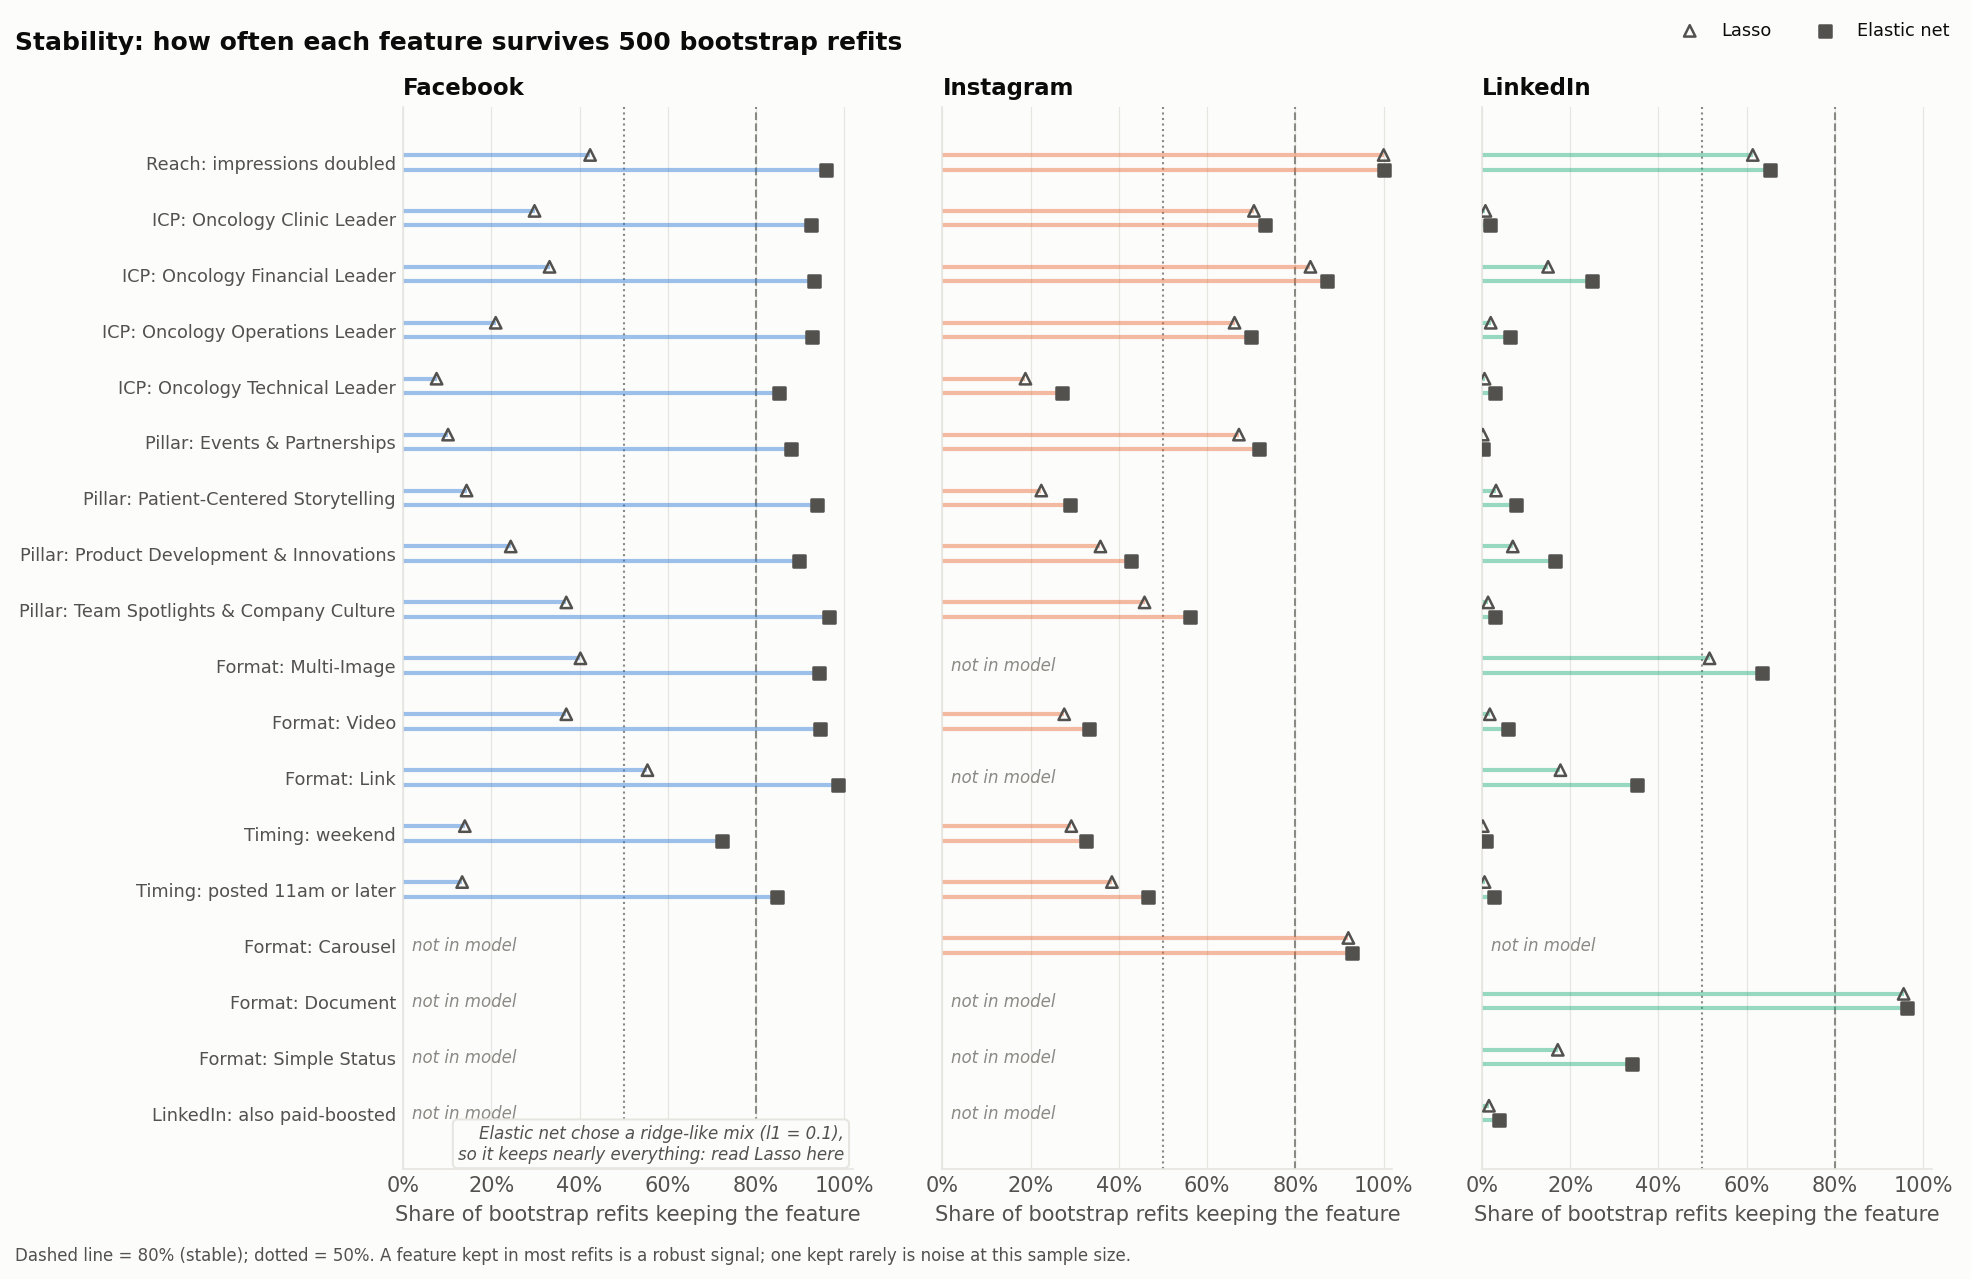

platform,feature,selection_freq,sign_agreement,boot_lo,boot_median,boot_hi
Instagram,Reach: impressions doubled,1.00,1.00,-7.60,-5.41,-4.02
Instagram,ICP: Oncology Financial Leader,0.83,1.00,-3.25,-1.11,-0.00
Instagram,Format: Carousel,0.92,1.00,0.00,2.33,5.52
LinkedIn,Format: Document,0.96,1.00,0.00,8.99,18.10
pooled,Reach: impressions doubled,1.00,1.00,-2.55,-1.52,-0.92
pooled,Format: Multi-Image,0.90,1.00,0.00,2.22,5.18
pooled,Format: Video,1.00,1.00,-4.64,-3.14,-1.35
pooled,Format: Link,0.88,0.99,-6.98,-3.03,-0.00
pooled,Format: Carousel,0.86,1.00,0.00,2.10,6.41
pooled,Format: Document,0.99,1.00,1.25,8.72,18.94


In [8]:
fig(MAIN, "stability_by_platform.png")
stab = read(MAIN, "stability.csv")
robust_stab = stab[(stab["model"] == "Lasso") & (stab["selection_freq"] >= 0.8) & (stab["sign_agreement"] >= 0.95)]
display(robust_stab.assign(feature=robust_stab["feature"].map(lab))
        [["platform", "feature", "selection_freq", "sign_agreement", "boot_lo", "boot_median", "boot_hi"]]
        .reset_index(drop=True).style.format(precision=2).hide(axis="index")
        .set_caption("Kept in ≥80% of lasso refits with ≥95% sign agreement"))

## 6. Robustness: sensitivity variants
Each variant changes one thing: add the experiment-period flag, weight by impressions, model log(1 + rate),
remove the reach control, or drop the single most influential post. The chart shows OLS effects of the key
features; the table counts in how many variants each finding keeps a CI clear of 0 with the same sign.

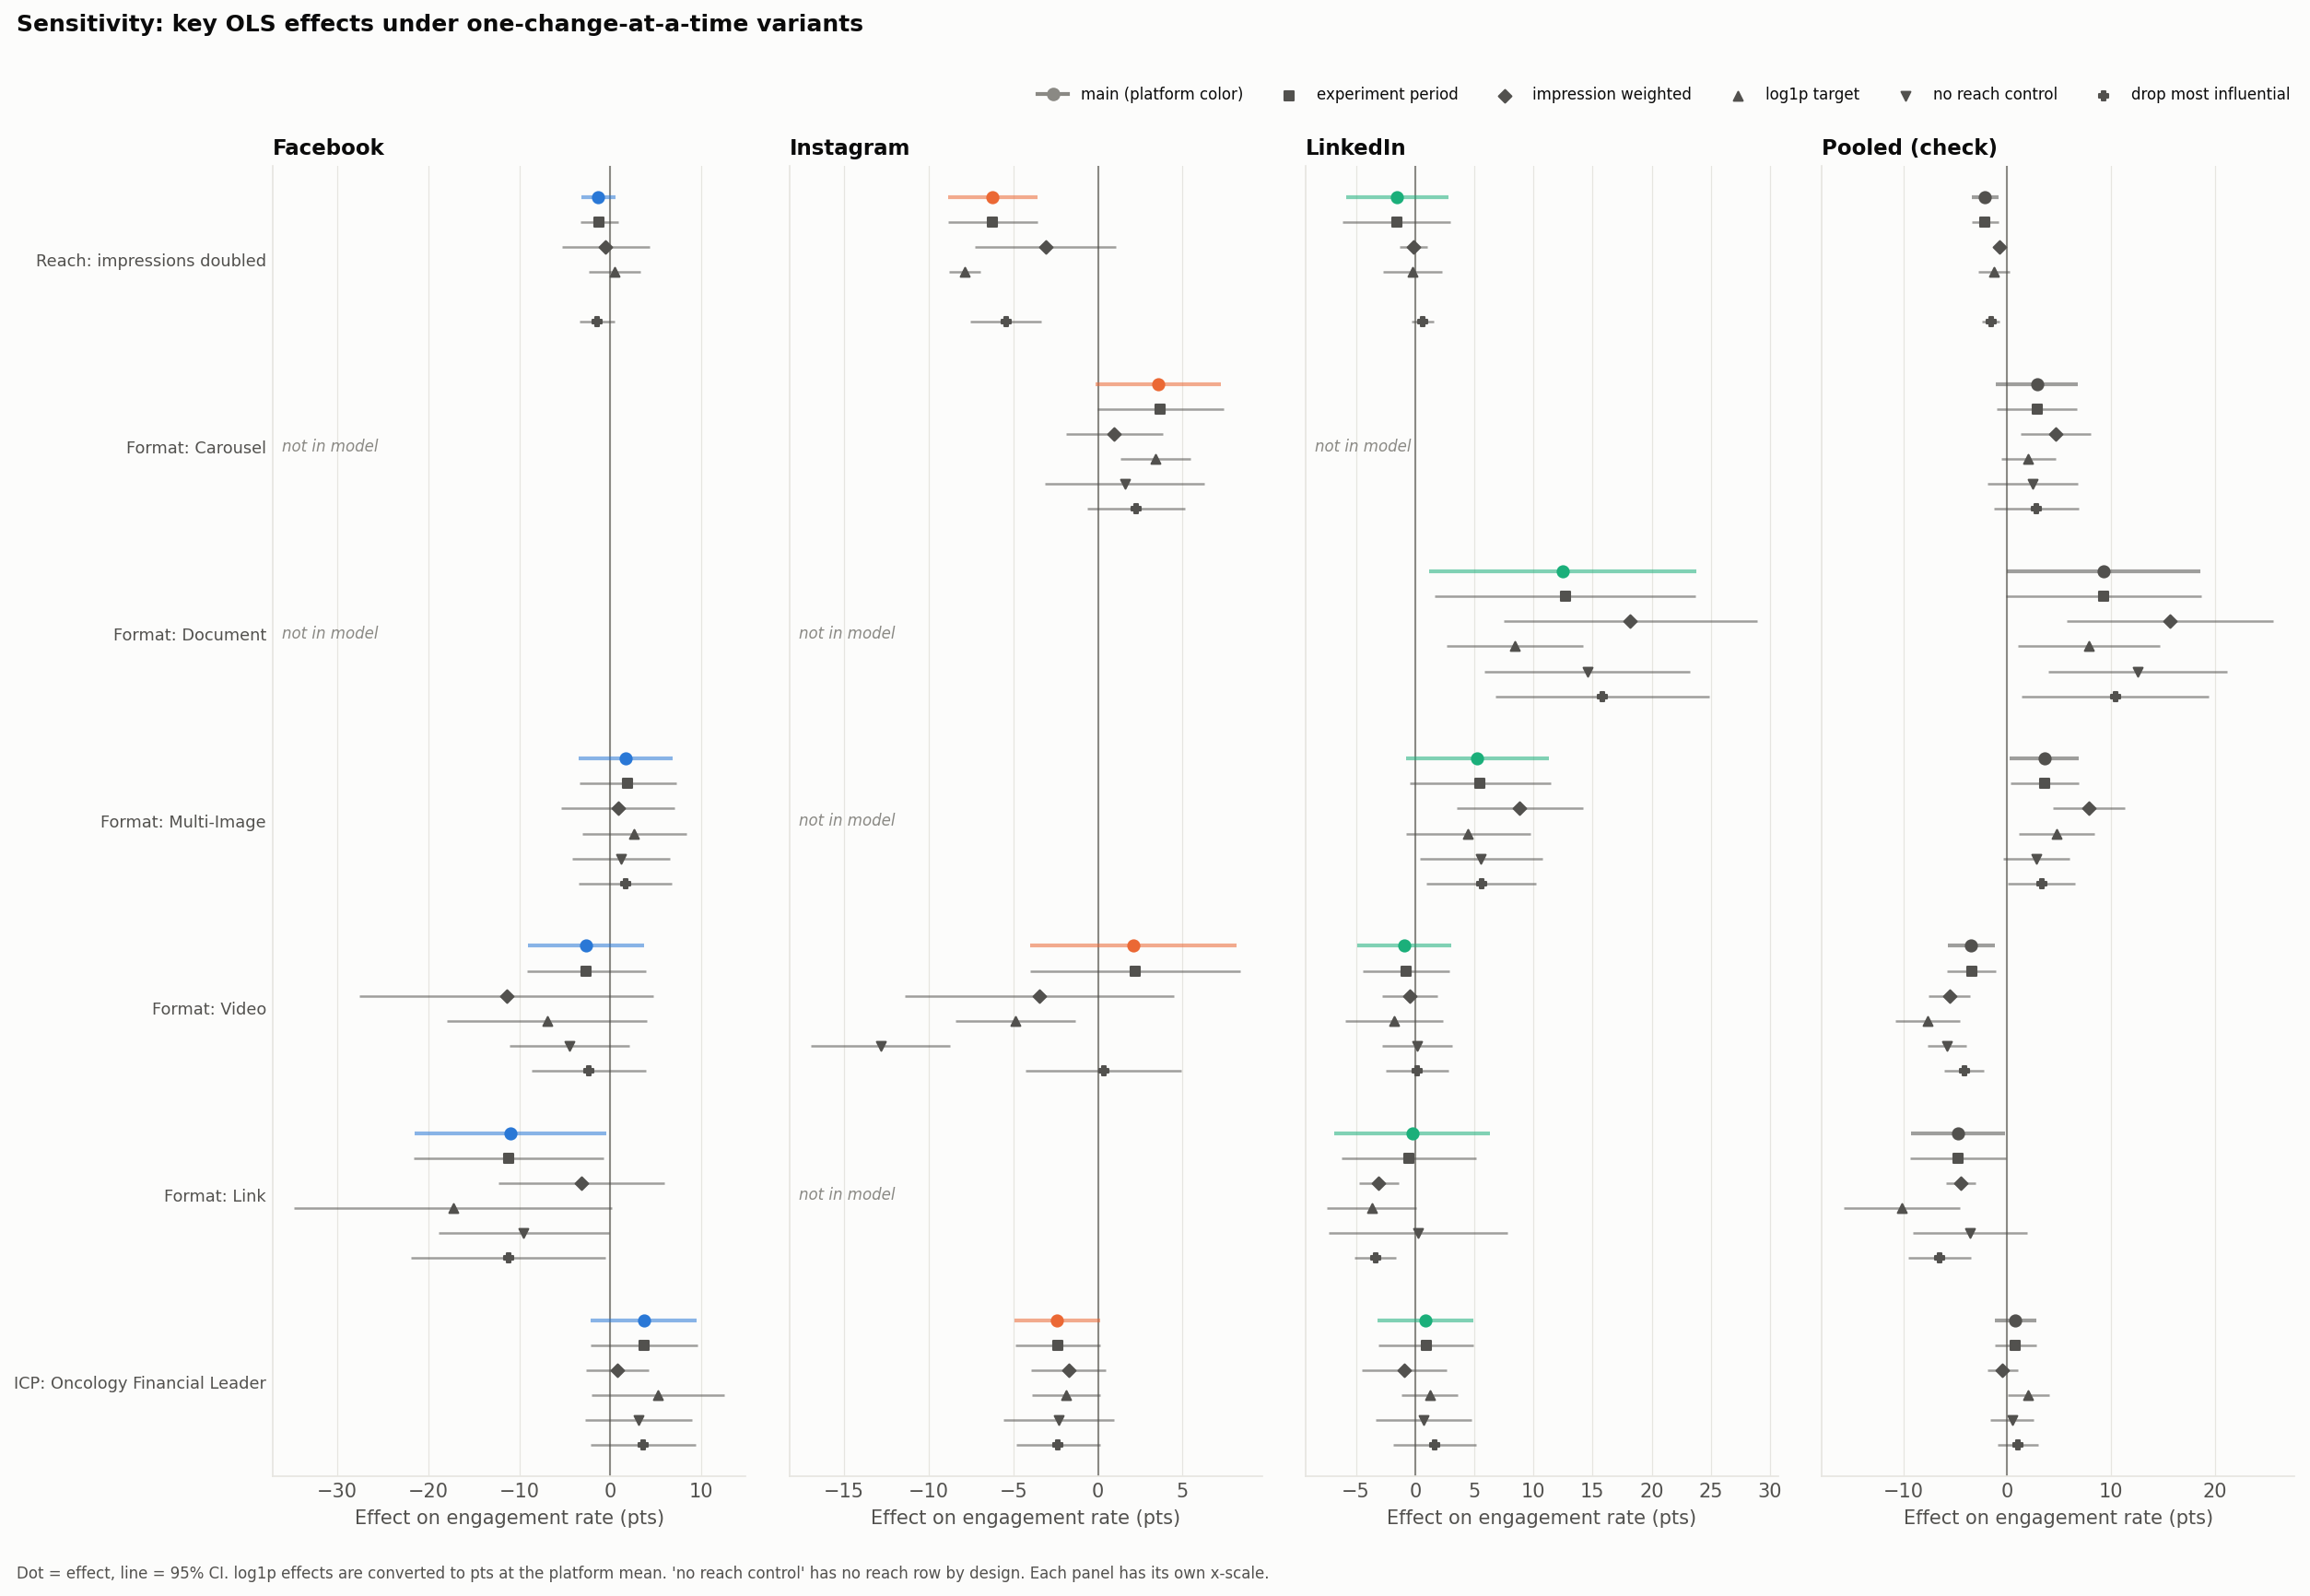

platform,feature,main_coef_pts,main_ci_excludes_0,variants,same_sign,ci_excludes_0_same_sign,variants_losing_it
Facebook,Reach: impressions doubled,-1.31,False,4,3,0,"experiment_period, impression_weighted, log1p_target, drop_most_influential"
Facebook,ICP: Oncology Financial Leader,3.68,False,5,5,0,"experiment_period, impression_weighted, log1p_target, no_reach_control, drop_most_influential"
Facebook,Format: Multi-Image,1.70,False,5,5,0,"experiment_period, impression_weighted, log1p_target, no_reach_control, drop_most_influential"
Facebook,Format: Video,-2.68,False,5,5,0,"experiment_period, impression_weighted, log1p_target, no_reach_control, drop_most_influential"
Facebook,Format: Link,-10.97,True,5,5,3,"impression_weighted, log1p_target"
Instagram,Reach: impressions doubled,-6.22,True,4,4,3,impression_weighted
Instagram,ICP: Oncology Financial Leader,-2.42,False,5,5,0,"experiment_period, impression_weighted, log1p_target, no_reach_control, drop_most_influential"
Instagram,Format: Carousel,3.57,False,5,5,1,"experiment_period, impression_weighted, no_reach_control, drop_most_influential"
Instagram,Format: Video,2.09,False,5,2,0,"experiment_period, impression_weighted, log1p_target, no_reach_control, drop_most_influential"
LinkedIn,Reach: impressions doubled,-1.51,False,4,3,0,"experiment_period, impression_weighted, log1p_target, drop_most_influential"


platform,Facebook,Instagram,LinkedIn,pooled
elastic net held-out R²,,,,
main,-0.052,0.438,-0.005,0.241
experiment_period,-0.054,0.436,-0.003,0.239
impression_weighted,-0.075,0.314,0.085,0.102
log1p_target,-0.256,0.569,0.060,0.152
no_reach_control,-0.055,0.108,0.084,0.187
drop_most_influential,-0.112,0.450,0.187,0.263


,platform,post dropped (master row)
0,Facebook,38
1,Instagram,374
2,LinkedIn,48
3,pooled,48


In [9]:
fig(SENS, "sensitivity_key_effects.png", width=1150)
rob = read(SENS, "robustness_summary.csv")
display(rob.assign(feature=rob["feature"].map(lab), variants_losing_it=rob["variants_losing_it"].fillna("none"))
        [["platform", "feature", "main_coef_pts", "main_ci_excludes_0", "variants", "same_sign",
          "ci_excludes_0_same_sign", "variants_losing_it"]]
        .style.format(precision=2).hide(axis="index"))
scv = read(SENS, "sensitivity_cv.csv")
display(scv.pivot(index="variant", columns="platform", values="r2_mean")
        .reindex(list(CONFIG["sensitivity"]["variants"])).rename_axis("elastic net held-out R²"))
dropped = read(SENS, "variant_notes.csv").dropna(subset=["dropped_master_rows"])
display(dropped.assign(dropped_master_rows=dropped["dropped_master_rows"].astype(int))
        [["platform", "dropped_master_rows"]].rename(columns={"dropped_master_rows": "post dropped (master row)"})
        .reset_index(drop=True))

## 7. Diagnostics
Residuals vs. fitted, normal Q-Q, and Cook's distance for the baseline OLS. LinkedIn has a heavy right tail
driven by one 3-impression post (master row 48). Instagram's linear reach term over-predicts at very high reach (a
fitted value below 0%), which is the reason the log1p variant fits Instagram better. No posts were removed from the
main models; influence is handled by the sensitivity variant.

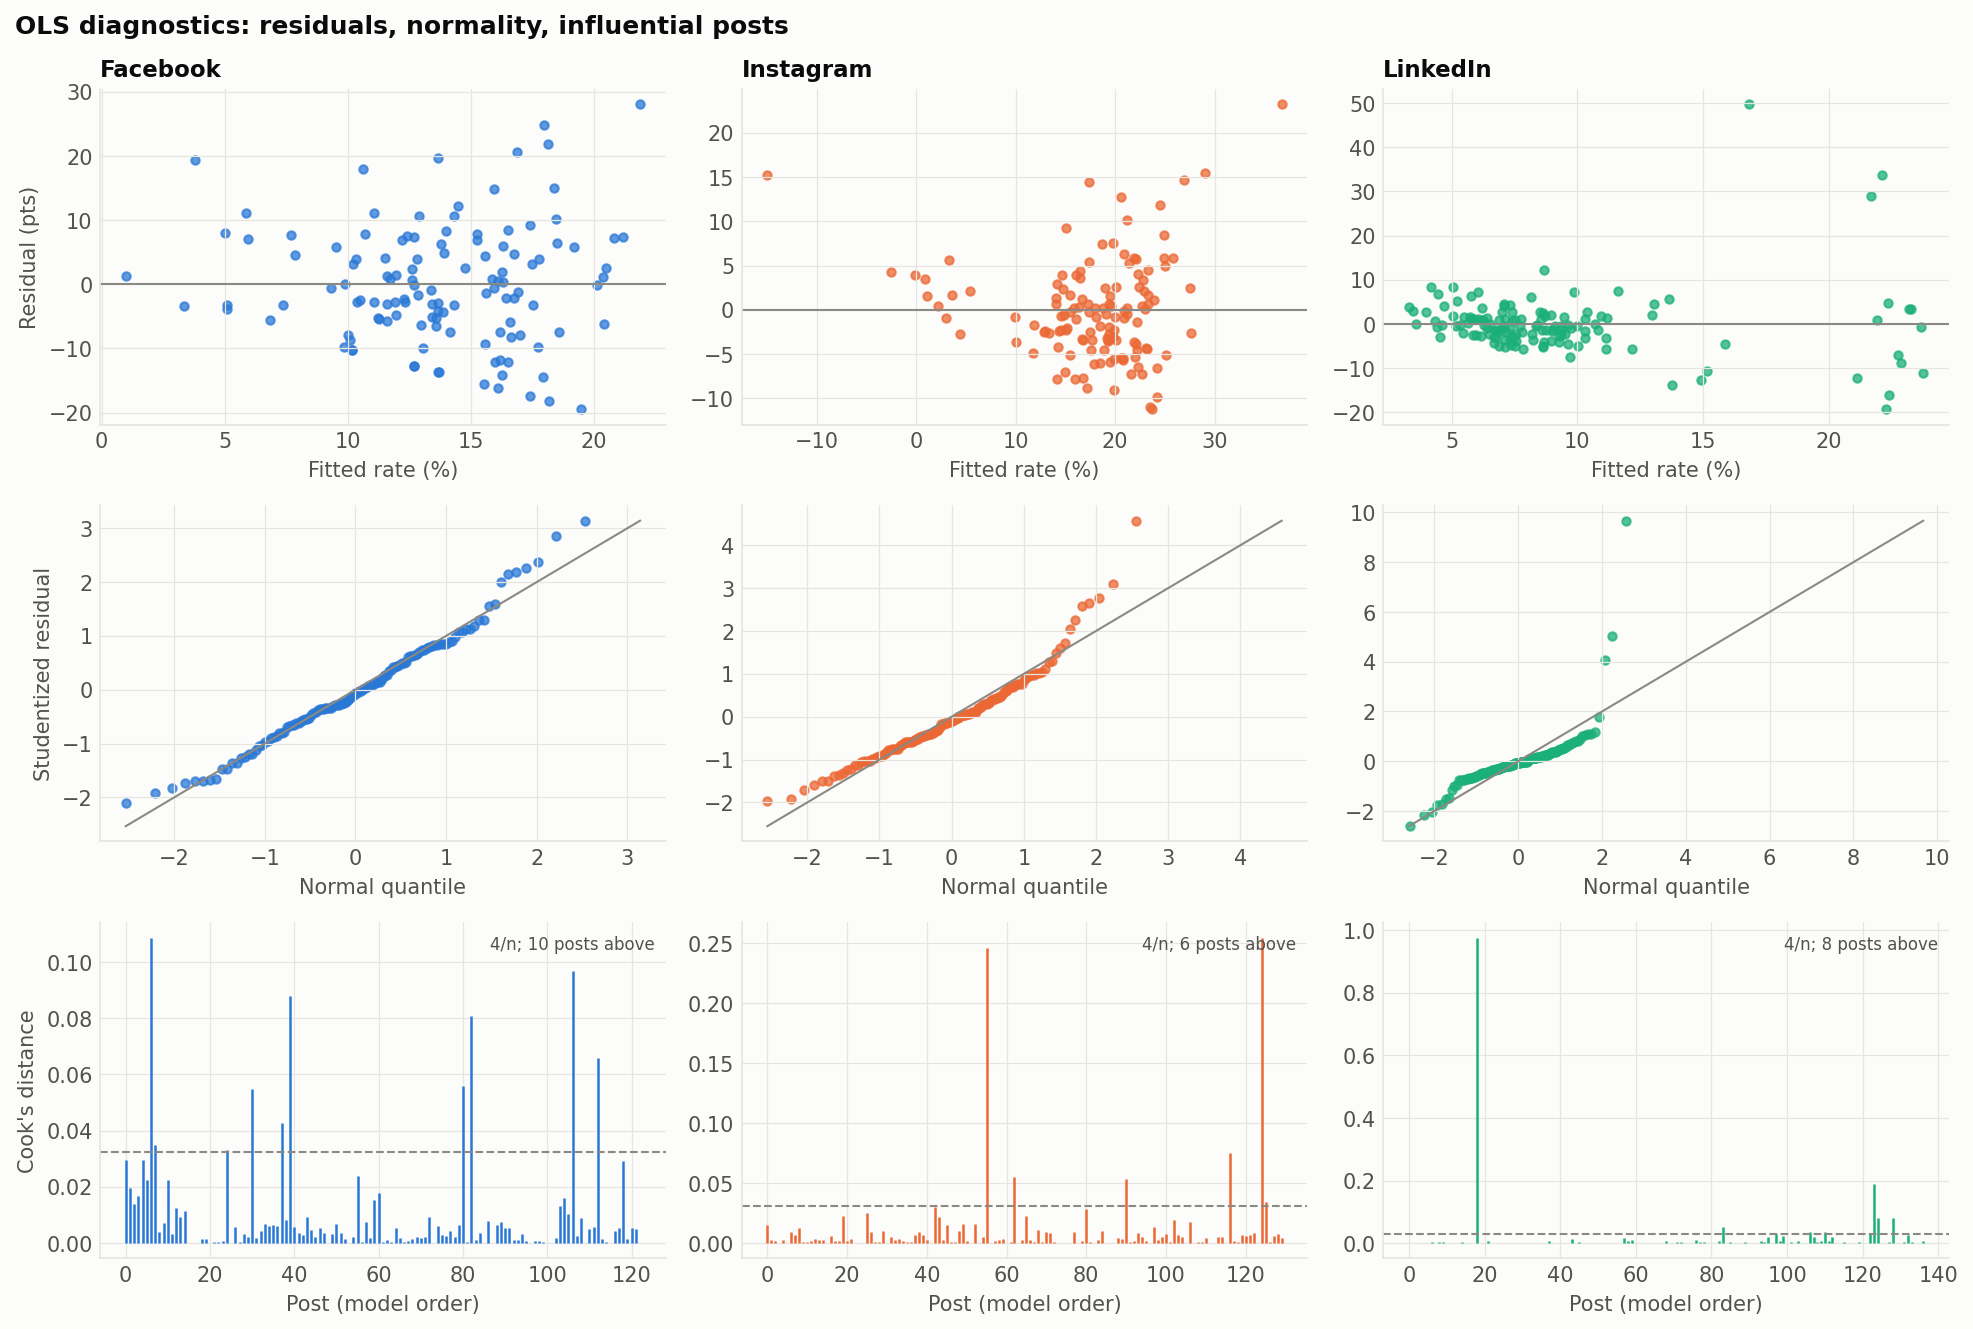

In [10]:
fig(MAIN, "diagnostics_ols.png", width=1000)

## 8. Conclusions

**Robust findings** (consistent across OLS, regularized models, bootstrap stability, permutation importance, and
sensitivity variants):

1. **LinkedIn Document posts engage much more:** about **+12 pts** over Image posts (range +8 to +18 across
   variants; kept in 96% of refits). It holds with the experiment-period flag in the model (the flag itself ≈ 0),
   so it is not a general Q2–Q3 lift. *Caveat:* all 13 Document posts ran Jul–Sep 2026, so a Jul–Sep-specific
   factor cannot be fully ruled out. More Document posts outside that window would settle it.
2. **On Instagram, reach drives the rate:** about **−6 pts per doubling of impressions** (kept in 100% of refits;
   the most important feature by far). High-reach posts engage at lower rates, so raw rates overstate small posts.
3. **Video's low rate is about reach, not content.** Within each platform video is not significantly different once
   impressions are controlled. Removing the reach control makes Instagram video look ≈ −13 pts.

**Suggestive, not robust:** Instagram Carousel (+2 to +4 pts; positive in every variant but CI usually crosses 0),
LinkedIn Multi-Image (+5 pts; 3 of 5 variants), Facebook Link (−11 pts; 8 posts, fragile).

**No detectable effect at this sample size:** ICP segment, content pillar, posting day/time, paid boost, and the
experiment period. Three independent checks agree: OLS CIs, bootstrap stability, and permutation importance.

**Facebook engagement is not predictable from these features**: a finding, not a failure.

**Implications for the next stages**
- *Stage 1 classification* (high vs. low engagement) can reuse `modeling/features.py` unchanged with a binary
  target. Expect it to be most useful on Instagram and LinkedIn.
- *Stage 2 recommendations* should rank by format and expected reach, treat segment/pillar choices as strategic
  (not predicted to change engagement rate), and flag LinkedIn Documents as the strongest lever to keep testing,
  ideally spread across months to separate format from timing.

## 9. Stage 2 preview: scoring hypothetical posts
`features_from_spec` encodes a planned post exactly like a real one (tested), so a fitted model can score
candidates. Here we refit the LinkedIn elastic net (penalty chosen on the shared CV splits, same as the run) and
**check it reproduces the committed coefficients**, then score a few hypothetical LinkedIn posts with typical reach.

In [11]:
from modeling.features import build_features, features_from_spec, load_master, prepare_posts  # noqa: E402
from modeling.models import cv_splits, fit_regularized, regularized_coef_table  # noqa: E402

posts, li_detail, _ = load_master(CONFIG)
prepared = prepare_posts(posts, li_detail, CONFIG)
fs = build_features(prepared, "LinkedIn", CONFIG)
splits = cv_splits(fs, CONFIG["cv"]["n_splits"], CONFIG["cv"]["n_repeats"], CONFIG["seed"])
pipe = fit_regularized(fs, "Elastic net", CONFIG, splits)

committed = read(MAIN, "coefficients_regularized.csv").query("platform == 'LinkedIn' and model == 'Elastic net'")
np.testing.assert_allclose(regularized_coef_table(pipe, fs, "Elastic net")["coef_pts"].to_numpy(),
                           committed["coef_pts"].to_numpy(), rtol=1e-9, atol=1e-12)
print("Refit reproduces the committed LinkedIn elastic-net coefficients exactly.")

typical = int(prepared.loc[prepared["PLATFORM"] == "LinkedIn", "IMPRESSIONS"].median())
base = {"icp": ["Oncology Operations Leader"], "pillars": ["Thought Leadership & Industry Insights"],
        "impressions": typical, "weekend": False, "hour": 9, "boosted": False}
candidates = pd.DataFrame([{**base, "format": f} for f in ["Image", "Document", "Multi-Image", "Video", "Link"]])
candidates["predicted_rate_pct"] = [pipe.predict(features_from_spec(c, "LinkedIn", CONFIG).to_numpy())[0]
                                    for c in candidates.to_dict("records")]
display(candidates[["format", "impressions", "predicted_rate_pct"]].sort_values("predicted_rate_pct", ascending=False)
        .style.format({"predicted_rate_pct": "{:.1f}"}).hide(axis="index")
        .set_caption(f"LinkedIn, Operations Leader × Thought Leadership, {typical} impressions (median), weekday 9am"))

Refit reproduces the committed LinkedIn elastic-net coefficients exactly.


format,impressions,predicted_rate_pct
Document,248,17.5
Multi-Image,248,9.2
Image,248,8.4
Video,248,8.4
Link,248,8.4


## 10. Reproduce
From the repo root (Python with pandas, numpy, statsmodels, scikit-learn, matplotlib, pyyaml):
```bash
python -m pytest modeling/tests -q                                     # 53 tests
python -m modeling.run_regression --tag <name>                         # steps 2–4 (~1 min)
python -m modeling.run_sensitivity --tag <name>                        # step 5 (~1 min)
```
Same master + same config + same code → byte-identical CSVs (checked during development). To use a new master
version, change `master:` in `modeling/config.yaml`, run the tests, then both commands with a new tag.